# EM local connectivity and WNM long-range projections

Slide figure pairing two matrices from the CCM release `ccm_v1.0.1_data_202611_v2`:

| Panel | Rows | Columns | Values |
|---|---|---|---|
| **EM (MICrONS minnie65, mat. 1822)** | proofread axons (presynaptic) | single-soma neurons (postsynaptic) | synapse count → scatter |
| **WNM (VISp excitatory, ipsilateral)** | whole-neuron reconstructions | CCF brain regions | axon length (µm) → heatmap |

EM cells are annotated with their own `minnie65_v1822_cell_types` cluster labels (no MET types).
WNM cells are annotated with their MET-type mapping. Brain regions are ordered and coloured by
the Harris et al. module order in `data/BrainRegionColors/harris_order_smgrouped.csv`.

The notebook only **reads** CCM tables. Figures are written to `figures/` next to this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

from connects_common_connectivity.config import find_config_file
from connects_common_connectivity.io import (
    DatasetReader,
    read_cell_cell_connectivity,
    read_spatial_locations,
)
from connects_common_connectivity.io.path_spec import MODEL_TABLE_PATHS

import plot_utils as pu

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(70)
pl.Config.set_tbl_width_chars(160)

REPO_ROOT = find_config_file().parent
OUTPUT_ROOT = REPO_ROOT / "scratch" / "ccm_v1.0.1_data_202611_v2"
HARRIS_CSV = REPO_ROOT / "data" / "BrainRegionColors" / "harris_order_smgrouped.csv"
FIG_DIR = Path("figures")
assert OUTPUT_ROOT.is_dir(), f"Missing release: {OUTPUT_ROOT}"
print(OUTPUT_ROOT)

/sessions/blissful-funny-planck/mnt/ConnectsCommonConnectivity/scratch/ccm_v1.0.1_data_202611_v2


## 1. What is in the release

`DatasetReader` is the dataset-centric entry point: list datasets, then discover which feature
sets and cluster sets overlap each dataset's data items.

In [2]:
reader = DatasetReader(OUTPUT_ROOT)
reader.display_dataset_names()

id,name,project_id,modality
str,str,str,str
"""barseq_visp_qc""","""BARseq VISp: 1,448 QC neurons from brains 777552 and 824690""","""barseq_visp""","""BARCODED"""
"""minnie65_v1822_proofread_axons""","""Minnie65 materialization 1822 proofread axons""","""minnie65""","""ELECTRON_MICROSCOPY"""
"""minnie65_v1822_single_soma_neurons""","""Minnie65 materialization 1822 single soma neurons""","""minnie65""","""ELECTRON_MICROSCOPY"""
"""v1dd_1196_proofread_axons""","""V1DD release 1196 - proofread axons cohort""","""v1dd_1196""","""ELECTRON_MICROSCOPY"""
"""v1dd_1196_single_soma_neurons""","""V1DD release 1196 - single soma neurons cohort""","""v1dd_1196""","""ELECTRON_MICROSCOPY"""
"""visp_exc_patchseq""","""VISp excitatory Patch-seq cells""","""visp_exc_morphology""","""MORPHOLOGY"""
"""visp_exc_wnm""","""VISp excitatory whole-neuron morphology cells""","""visp_exc_morphology""","""MORPHOLOGY"""
"""visp_inh_patchseq""","""VISp inhibitory Patch-seq cells""","""visp_patchseq""","""MORPHOLOGY"""


In [3]:
# Datasets used in this figure
EM_PROJECT = "minnie65"
EM_PRE_DATASET = "minnie65_v1822_proofread_axons"        # rows (presynaptic)
EM_POST_DATASET = "minnie65_v1822_single_soma_neurons"   # columns (postsynaptic)
EM_CONNECTOME = "minnie65_v1822_proofread_axon_to_single_soma"
EM_HIERARCHY = "minnie65_v1822_cell_types"

WNM_PROJECT = "visp_exc_morphology"
WNM_DATASET = "visp_exc_wnm"
WNM_PROJECTION = "wnm_exc_proj_ipsi"
WNM_MET_MAPPING = "visp_exc_wnm_mettype_mapping"
MET_HIERARCHY = "visp_met_types_taxonomy"

### 1a. Feature names — EM (minnie65)

`display_featuresets` returns one row per feature matrix that overlaps the dataset; the
`feature_definition_ids` column holds the feature names.

In [4]:
em_featuresets = reader.display_featuresets(EM_PRE_DATASET)
em_featuresets.select(
    "feature_set_id", "extraction_method",
    pl.col("feature_definition_ids").list.len().alias("n_features"),
)

feature_set_id,extraction_method,n_features
str,str,u32
"""minnie65_v1822_morphology_features""","""Cached minnie_features.parquet morphology pipeline""",82
"""minnie65_v1822_nucleus_volume""","""CAVE nucleus_detection_v0 at materialization 1822""",1


In [5]:
def feature_names(featuresets: pl.DataFrame) -> pl.DataFrame:
    # Explode feature sets to one row per feature, with definitions (unit, description).
    definitions = pl.read_delta(str(OUTPUT_ROOT / MODEL_TABLE_PATHS["CellFeatureDefinition"]))
    return (
        featuresets.select("feature_set_id", pl.col("feature_definition_ids").alias("feature"))
        .explode("feature")
        .join(
            definitions.select(
                pl.col("feature_set_id"), pl.col("id").alias("feature"), "unit", "description"
            ),
            on=["feature_set_id", "feature"],
            how="left",
        )
    )


em_feature_names = feature_names(em_featuresets)
print(f"{em_feature_names.height} EM features")
em_feature_names

83 EM features


feature_set_id,feature,unit,description
str,str,str,str
"""minnie65_v1822_morphology_features""","""nucleus_volume_um""","""MICRONS_CUBED""","""Nucleus volume"""
"""minnie65_v1822_morphology_features""","""nucleus_area_um""","""MICRONS_SQUARE""","""Nucleus surface area"""
"""minnie65_v1822_morphology_features""","""nuclear_area_to_volume_ratio""","""MICRONS_INVERSE""","""Nucleus surface area to volume ratio"""
"""minnie65_v1822_morphology_features""","""nuclear_folding_area_um""","""MICRONS_SQUARE""","""Area of nucleus in an infolding (see Elabbady et al paper)"""
"""minnie65_v1822_morphology_features""","""fraction_nuclear_folding""","""RATIO""","""Fraction of nucleus in an infolding"""
"""minnie65_v1822_morphology_features""","""nucleus_to_soma_ratio""","""RATIO""","""Ratio of the nucleus volume to the soma volume"""
"""minnie65_v1822_morphology_features""","""soma_volume_um""","""MICRONS_CUBED""","""Soma volume including nucleus"""
"""minnie65_v1822_morphology_features""","""soma_area_um""","""MICRONS_SQUARE""","""Soma surface area"""
"""minnie65_v1822_morphology_features""","""soma_to_nucleus_center_dist""","""MICRONS_LENGTH""","""Distance between soma centroid and nucleus centroid"""


### 1b. Feature names — WNM (VISp excitatory)

In [6]:
wnm_featuresets = reader.display_featuresets(WNM_DATASET)
wnm_feature_names = feature_names(wnm_featuresets)
print(wnm_feature_names.group_by("feature_set_id").len().sort("feature_set_id"))
wnm_feature_names.filter(pl.col("feature_set_id") == "wnm_exc_local_axon_features")

shape: (3, 2)
┌────────────────────────────────┬─────┐
│ feature_set_id                 ┆ len │
│ ---                            ┆ --- │
│ str                            ┆ u32 │
╞════════════════════════════════╪═════╡
│ exc_visp_morph_features        ┆ 50  │
│ wnm_exc_complete_axon_features ┆ 18  │
│ wnm_exc_local_axon_features    ┆ 51  │
└────────────────────────────────┴─────┘


feature_set_id,feature,unit,description
str,str,str,str
"""wnm_exc_local_axon_features""","""apical_dendrite_bias_x""",null,"""apical dendrite bias x"""
"""wnm_exc_local_axon_features""","""apical_dendrite_bias_y""",null,"""apical dendrite bias y"""
"""wnm_exc_local_axon_features""","""apical_dendrite_depth_pc_0""",null,"""apical dendrite depth pc 0"""
"""wnm_exc_local_axon_features""","""apical_dendrite_depth_pc_1""",null,"""apical dendrite depth pc 1"""
"""wnm_exc_local_axon_features""","""apical_dendrite_depth_pc_2""",null,"""apical dendrite depth pc 2"""
"""wnm_exc_local_axon_features""","""apical_dendrite_depth_pc_3""",null,"""apical dendrite depth pc 3"""
"""wnm_exc_local_axon_features""","""apical_dendrite_depth_pc_4""",null,"""apical dendrite depth pc 4"""
"""wnm_exc_local_axon_features""","""apical_dendrite_early_branch_path""",null,"""apical dendrite early branch path"""
"""wnm_exc_local_axon_features""","""apical_dendrite_extent_x""",null,"""apical dendrite extent x"""


### 1c. Cluster sets, cell-type mappings and projection matrices

EM cell types are cluster *memberships* (found by `display_clustersets`). WNM MET types are
cell-to-cluster *mappings*, and projections live in `ProjectionMeasurementMatrix`; neither has
a `ccc.io` reader yet, so `plot_utils` reads them directly.

In [7]:
display(reader.display_clustersets(EM_PRE_DATASET))
display(pu.list_projection_matrices(OUTPUT_ROOT).select(
    "id", "project_id", "laterality", "measurement_type", "unit", "n_cells", "n_regions"
))

clusterset_id,run,root,clusters
str,str,str,list[str]
"""minnie65_v1822_cell_types""","""minnie65_v1822_cell_type_annotation""","""neuron""","[""neuron"", ""exc"", … ""PV""]"


id,project_id,laterality,measurement_type,unit,n_cells,n_regions
str,str,str,str,str,u32,u32
"""wnm_exc_proj_contra""","""visp_exc_morphology""","""CONTRALATERAL""","""MICRONS_OF_AXON""","""MICRONS_LENGTH""",345,68
"""wnm_exc_proj_ipsi""","""visp_exc_morphology""","""IPSILATERAL""","""MICRONS_OF_AXON""","""MICRONS_LENGTH""",345,152
"""barseq_proj_429_total""","""barseq_visp""","""BILATERAL""","""DETECTIONS""","""COUNT""",1448,429
"""barseq_proj_18_contra""","""barseq_visp""","""CONTRALATERAL""","""DETECTIONS""","""COUNT""",1448,18
"""barseq_proj_18_ipsi""","""barseq_visp""","""IPSILATERAL""","""DETECTIONS""","""COUNT""",1448,18
"""barseq_proj_18_total""","""barseq_visp""","""BILATERAL""","""DETECTIONS""","""COUNT""",1448,18


## 2. Figure parameters

Change features, ordering and sizes here. Everything below reads from these values.

In [8]:
# --- EM panel -----------------------------------------------------------------
# (column, strip title, colormap). Columns come from the EM feature sets above, plus
# "soma_depth_um" (from read_spatial_locations).
# EM_FEATURE_SET is joined in full (nucleus volume: 100% coverage of the proofread axons).
# EM_EXTRA_FEATURES are taken from the morphology feature set, which covers only ~11% of the
# proofread axons in this release (missing cells are drawn light grey; coverage printed below).
# Every nuclear-folding measure (fraction_nuclear_folding, nuclear_folding_area_um,
# nuclear_area_to_volume_ratio) lives in that morphology set.
EM_FEATURE_SET = "minnie65_v1822_nucleus_volume"
EM_EXTRA_FEATURE_SET = "minnie65_v1822_morphology_features"
EM_EXTRA_FEATURES = []  # e.g. ["fraction_nuclear_folding"] (sparse, see above)
EM_STRIPS = [
    ("nucleus_volume_um", "Nucleus vol.", "viridis"),
]
EM_WITHIN_SORT = "soma_depth_um"  # order cells inside each cell type
EM_CLUSTER_ORDER = {
    "Excitatory": ["L2IT", "L3IT", "L4IT", "L5IT", "L5ET", "L5NP", "L6CT", "L6IT"],
    "Inhibitory": ["PV", "AltBasket", "ChC", "MC", "NMC", "DTC", "AltDTC", "ITC", "ITCperi",
                   "NGC", "L1"],
}
EM_DEPTH_SPACE = "minnie65_v1822_standard_transform_um"  # y = depth from pia (µm)

# --- WNM panel ----------------------------------------------------------------
WNM_FEATURE_SET = "wnm_exc_local_axon_features"
WNM_STRIPS = [
    ("axon_max_euclidean_distance", "Max Euc. dist.", "viridis"),
    ("axon_num_branches", "N branches", "magma"),
]
WNM_WITHIN_SORT = "soma_aligned_dist_from_pia"  # order cells inside each MET type
MIN_CELLS_PER_REGION = 5  # hide regions reached by fewer WNM cells (1 = all 152 regions)

# --- Layout (inches) and fonts (pt) ---------------------------------------------
GEOM = pu.PanelGeometry(
    main_w=5.0, main_h=5.0,
    strip_title_size=12, block_label_size=11, axis_label_size=13, caption_size=16,
    caption_drop=1.4,
)
LEGEND_FONTSIZE = 13
pu.use_presentation_style()

## 3. EM data — cells, features, cell types, connectivity

`read_dataset` returns one wide row per data item, joining the selected feature set and the
cluster set (`<hierarchy>_level_<n>` columns).

In [9]:
CLUSTER_COL = f"{EM_HIERARCHY}_level_2"

pre = reader.read_dataset(EM_PRE_DATASET, featuresets=EM_FEATURE_SET, clustersets=EM_HIERARCHY)
post = reader.read_dataset(EM_POST_DATASET, featuresets=[], clustersets=EM_HIERARCHY)

depth = read_spatial_locations(
    EM_PROJECT, reference_spaces=EM_DEPTH_SPACE, location_types="SOMA", output_root=OUTPUT_ROOT
).select("dataitem_id", pl.col("y").alias("soma_depth_um"))
pre = pre.join(depth, on="dataitem_id", how="left")
post = post.join(depth, on="dataitem_id", how="left")

# Extra features from a second feature set (joined separately: it also carries
# nucleus_volume_um, which read_dataset would reject as a duplicate column)
morph = reader.read_dataset(EM_PRE_DATASET, featuresets=EM_EXTRA_FEATURE_SET, clustersets=[])
pre = pre.join(morph.select("dataitem_id", *EM_EXTRA_FEATURES), on="dataitem_id", how="left")

edges = read_cell_cell_connectivity(
    EM_PROJECT, EM_CONNECTOME, measurement_types="SYNAPSE_COUNT", output_root=OUTPUT_ROOT
).select("presynaptic_cell", "postsynaptic_cell", "value")
print(f"pre: {pre.height:,} proofread axons | post: {post.height:,} single-soma neurons | "
      f"edges: {edges.height:,}")

# Feature coverage on the presynaptic cells
nuclear = ["fraction_nuclear_folding", "nuclear_folding_area_um", "nuclear_area_to_volume_ratio",
           "syn_size_distribution_dendrite_p50"]
coverage = {c: 1 - morph[c].null_count() / morph.height for c in nuclear}
coverage |= {c: 1 - pre[c].null_count() / pre.height for c, _, _ in EM_STRIPS}
print("feature coverage on presynaptic cells:", {k: f"{v:.0%}" for k, v in coverage.items()})

pre: 627 proofread axons | post: 81,059 single-soma neurons | edges: 590,180
feature coverage on presynaptic cells: {'fraction_nuclear_folding': '11%', 'nuclear_folding_area_um': '11%', 'nuclear_area_to_volume_ratio': '11%', 'syn_size_distribution_dendrite_p50': '11%', 'nucleus_volume_um': '100%'}


In [10]:
em_palette_df = pu.read_cluster_palette(OUTPUT_ROOT, EM_HIERARCHY, level=2)
em_palette = dict(zip(em_palette_df["id"], em_palette_df["hex_color"]))
em_class_of = dict(zip(em_palette_df["id"], em_palette_df["parent"]))
em_order = [c for group in EM_CLUSTER_ORDER.values() for c in group]
em_order += sorted(set(em_palette) - set(em_order))  # any new labels go last

keep = list(dict.fromkeys(["dataitem_id", CLUSTER_COL, EM_WITHIN_SORT]
                          + [c for c, _, _ in EM_STRIPS]))
pre_meta = pu.order_cells(
    pre.filter(pl.col(CLUSTER_COL).is_not_null()).select(keep).to_pandas(),
    cluster_col=CLUSTER_COL, cluster_order=em_order, within_col=EM_WITHIN_SORT,
)
targets = (
    edges.filter(pl.col("presynaptic_cell").is_in(pre_meta["dataitem_id"].tolist()))
    ["postsynaptic_cell"].unique()
)
post_meta = pu.order_cells(
    post.filter(pl.col(CLUSTER_COL).is_not_null() & pl.col("dataitem_id").is_in(targets.to_list()))
        .select("dataitem_id", CLUSTER_COL, "soma_depth_um").to_pandas(),
    cluster_col=CLUSTER_COL, cluster_order=em_order, within_col="soma_depth_um",
)
edges_pd = edges.to_pandas()
print(f"plotted: {len(pre_meta):,} pre × {len(post_meta):,} post "
      f"({pre.height - len(pre_meta)} pre without a cell-type label dropped)")
pre_meta[CLUSTER_COL].value_counts().reindex(em_order).dropna().astype(int).to_frame("n_pre").T

plotted: 625 pre × 52,047 post (2 pre without a cell-type label dropped)


minnie65_v1822_cell_types_level_2,L2IT,L3IT,L4IT,L5IT,L5ET,L6IT,PV,AltBasket,ChC,MC,NMC,DTC,ITC,NGC,L1
n_pre,123,67,197,45,13,5,93,4,1,51,13,2,6,1,4


## 4. WNM data — cells, features, MET types, ipsilateral projections

In [11]:
wnm_cells = reader.read_dataset(WNM_DATASET, featuresets=WNM_FEATURE_SET, clustersets=[])

met_palette_df = pu.read_cluster_palette(OUTPUT_ROOT, MET_HIERARCHY, level=2)
met_palette = dict(zip(met_palette_df["id"], met_palette_df["hex_color"]))
met = pu.read_cell_to_cluster(
    OUTPUT_ROOT, project_id=WNM_PROJECT, mapping_set=WNM_MET_MAPPING,
    cluster_ids=met_palette_df["id"].to_list(),
)
assert met["dataitem_id"].n_unique() == met.height, "expected one MET type per WNM cell"

proj_meta, proj = pu.read_projection_matrix(OUTPUT_ROOT, WNM_PROJECTION)
region_cols = [c for c in proj.columns if c not in ("id", "project_id", "dataset_id")]
print(f"{proj_meta['description']}  [{proj_meta['unit']}]  {proj.height} cells × {len(region_cols)} regions")

met_order = (
    met_palette_df.filter(pl.col("parent") == "Glutamatergic")["id"].sort().to_list()
)
wnm_meta = pu.order_cells(
    wnm_cells.join(met.rename({"cluster": "met_type"}), on="dataitem_id", how="inner")
        .filter(pl.col("dataitem_id").is_in(proj["id"].to_list()))
        .select("dataitem_id", "met_type", WNM_WITHIN_SORT, *[c for c, _, _ in WNM_STRIPS])
        .to_pandas(),
    cluster_col="met_type", cluster_order=met_order, within_col=WNM_WITHIN_SORT,
)
print(f"WNM cells with features + MET type + projections: {len(wnm_meta)}")

WNM excitatory ipsilateral per-cell axon projection by CCF region.  [MICRONS_LENGTH]  345 cells × 152 regions
WNM cells with features + MET type + projections: 341


In [12]:
regions_all = pu.region_groups_table(region_cols, HARRIS_CSV)
proj_pd = proj.to_pandas().set_index("id").loc[wnm_meta["dataitem_id"], regions_all["region"]]
n_cells_per_region = (proj_pd > 0).sum(axis=0).to_numpy()
regions = regions_all[n_cells_per_region >= MIN_CELLS_PER_REGION].reset_index(drop=True)
wnm_matrix = proj_pd[regions["region"]].to_numpy(dtype=float)

kept = wnm_matrix.sum() / proj_pd.to_numpy().sum()
print(f"regions shown: {len(regions)} / {len(regions_all)} "
      f"(≥{MIN_CELLS_PER_REGION} cells; {kept:.1%} of total ipsilateral axon length)")
print("unassigned regions:", regions_all.loc[regions_all["group"] == "Other", "region"].tolist())
regions.groupby("group", sort=False).size().to_frame("n_regions").T

regions shown: 79 / 152 (≥5 cells; 99.0% of total ipsilateral axon length)
unassigned regions: []


group,Anterolateral,Somatomotor,Visual,Medial,Auditory,Hippocampal,Cortical subplate,Striatum & pallidum,Thalamus,Hypothalamus,Midbrain,Hindbrain,Fiber tracts
n_regions,2,8,10,5,5,5,1,2,18,2,16,4,1


## 5. Figures

Each panel is drawn by a function that takes the figure and the bottom-left corner of its
matrix in inches, so the same code makes the individual panels and the combined slide figure.

In [13]:
from dataclasses import replace


def em_legend_sections():
    present = set(pre_meta[CLUSTER_COL]) | set(post_meta[CLUSTER_COL])
    return [(group, [(c, em_palette[c]) for c in names if c in present])
            for group, names in EM_CLUSTER_ORDER.items()]


def draw_em(fig, x0, y0, legend_x, geom=GEOM):
    strips = [pu.StripSpec(c, t, cmap=cm) for c, t, cm in EM_STRIPS]
    strips.append(pu.StripSpec(CLUSTER_COL, "EM cell type", kind="category", palette=em_palette))
    axes = pu.plot_connectivity_panel(
        fig, origin=(x0, y0), row_meta=pre_meta, col_meta=post_meta, edges=edges_pd,
        cluster_col=CLUSTER_COL, palette=em_palette, strips=strips, class_of=em_class_of,
        geometry=geom, row_label="Presynaptic proofread axons",
        col_label="Postsynaptic single-soma neurons",
        caption=f"Cell → cell connectivity  ({len(pre_meta):,} × {len(post_meta):,})",
    )
    lax = pu.InchAxes(fig).add(legend_x, y0, 1.2, GEOM.main_h + GEOM.top_strip_h)
    pu.add_legend(lax, em_legend_sections(), title="EM cell types", fontsize=LEGEND_FONTSIZE)
    return axes


def draw_wnm(fig, x0, y0, legend_x):
    strips = [pu.StripSpec(c, t, cmap=cm) for c, t, cm in WNM_STRIPS]
    strips.append(pu.StripSpec("met_type", "MET type", kind="category", palette=met_palette))
    axes = pu.plot_projection_panel(
        fig, origin=(x0, y0), row_meta=wnm_meta, matrix=wnm_matrix, regions=regions,
        cluster_col="met_type", strips=strips, geometry=GEOM, vmin=100, vmax=1e5,
        colorbar_label="Ipsilateral axon length (µm)",
        caption=f"Cell → brain area projections  ({wnm_matrix.shape[0]:,} × {wnm_matrix.shape[1]:,})",
    )
    canvas = pu.InchAxes(fig)
    present = list(dict.fromkeys(wnm_meta["met_type"]))
    lax = canvas.add(legend_x, y0, 1.75, GEOM.main_h + GEOM.top_strip_h)
    pu.add_legend(lax, [(None, [(m, met_palette[m]) for m in present])], title="MET types",
                  fontsize=LEGEND_FONTSIZE)
    groups = regions.drop_duplicates("group")
    gax = canvas.add(x0 + 2.35, y0 - 0.95, GEOM.main_w - 2.35, 0.8)
    pu.add_legend(gax, [(None, list(zip(groups["group"], groups["group_color"])))],
                  fontsize=LEGEND_FONTSIZE - 2, ncol=3, loc="upper left")
    return axes

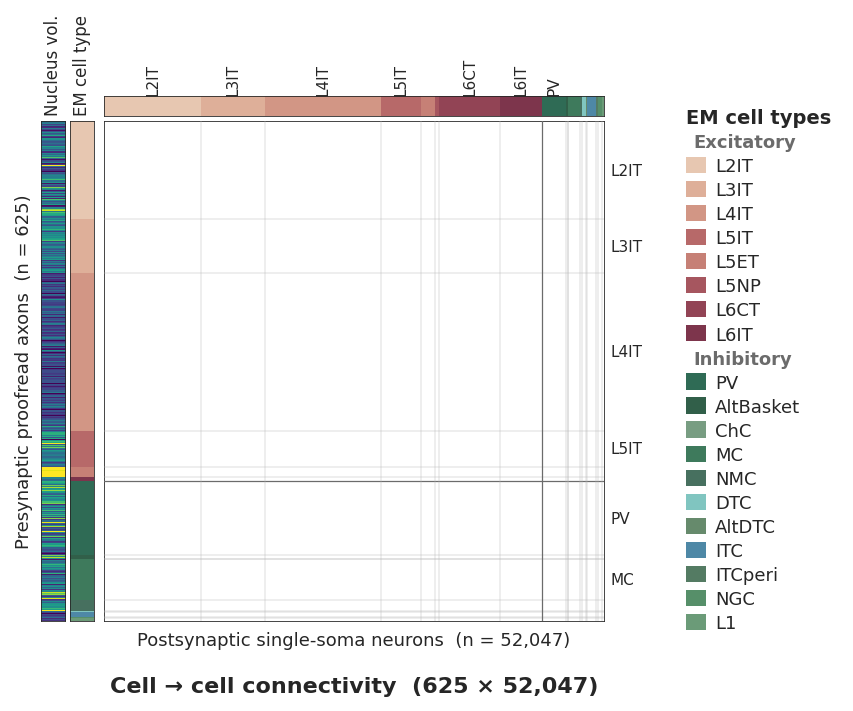

In [14]:
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")

# EM panel alone
# (caption sits closer here; in the combined figure it is aligned with the WNM caption)
fig = plt.figure(figsize=(9.0, 7.85))
draw_em(fig, x0=1.45, y0=1.6, legend_x=1.45 + GEOM.main_w + 0.75,
        geom=replace(GEOM, caption_drop=0.55))
save(fig, "em_minnie65_connectivity")
plt.show()

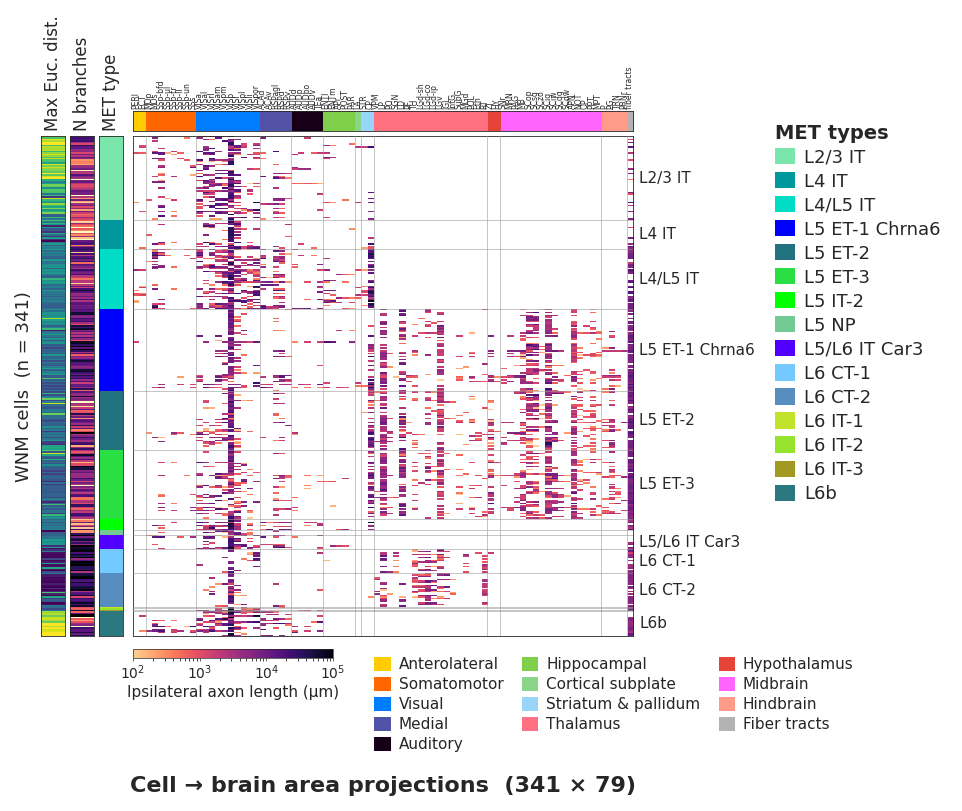

In [15]:
# WNM panel alone
fig = plt.figure(figsize=(9.9, 7.85))
draw_wnm(fig, x0=1.75, y0=1.6, legend_x=1.75 + GEOM.main_w + 1.35)
save(fig, "wnm_exc_ipsi_projections")
plt.show()

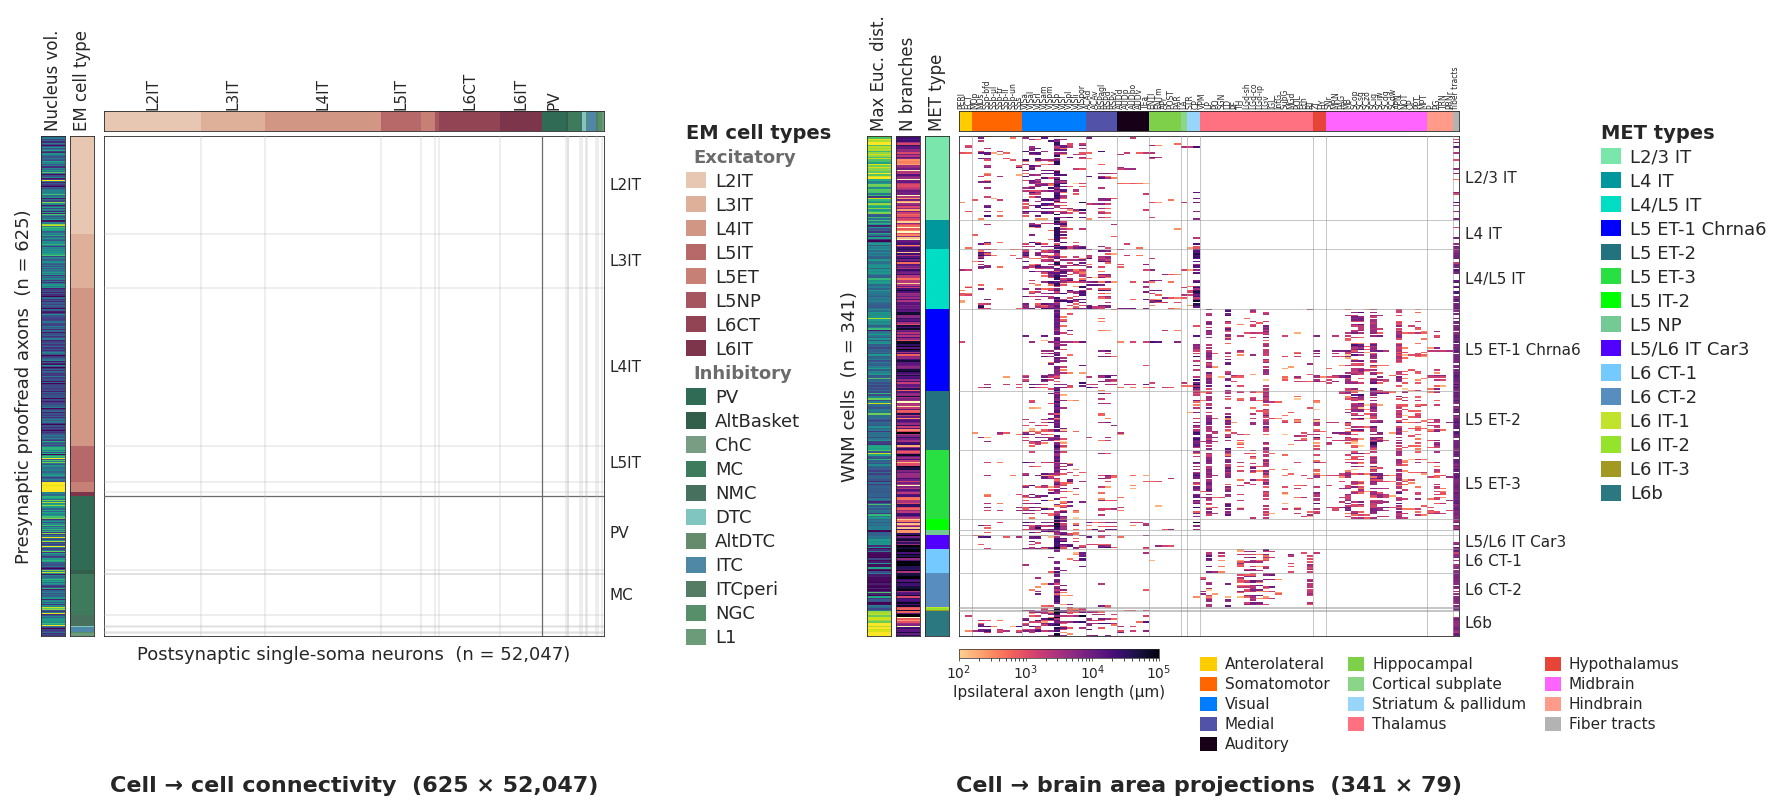

In [16]:
# Combined slide figure (16:9-friendly). Scale to slide width in PowerPoint; the PDF keeps
# text editable and the EM scatter rasterised at 300 dpi.
fig = plt.figure(figsize=(18.1, 7.85))
draw_em(fig, x0=1.45, y0=1.6, legend_x=1.45 + GEOM.main_w + 0.75)
draw_wnm(fig, x0=10.0, y0=1.6, legend_x=10.0 + GEOM.main_w + 1.35)
save(fig, "em_connectivity_wnm_projections")
plt.show()